#BERT

##Topik 0

###Training

In [ ]:
import pandas as pd
import numpy as np
import pickle
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from imblearn import over_sampling
from datasets import Dataset
from IPython.display import display
import random
import torch
from transformers import BertForSequenceClassification, BertConfig, BertTokenizer
from transformers import Trainer, TrainingArguments

# Reading product review sentiment file
df_topik0 = pd.read_csv('topik0.csv',\
                      encoding='latin-1')
display(df_topik0.sample(n=5, random_state=42))

,text,label_st1,sentiment
4365,fantastic product fantastic product leave room...,0,1
1129,amaze love game love movie may little still aw...,0,1
2602,good childrens movie get daughter love theater...,0,1
1747,love smell love smell usually really enjoy aus...,0,1
3286,dat roar tho saw movie time still love cant ...,0,1


In [ ]:
x=df_topik0['text']
y=df_topik0['sentiment']
print("Checking distribution of +ve and -ve review sentiment: \n{}".format(y.value_counts(normalize=True)))
# Split the dataset into test and train
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=50)

# As we saw above that data is imbalanced, balance training data using over sampling

ros = over_sampling.RandomOverSampler(random_state=0)
X_train, y_train = ros.fit_resample(pd.DataFrame(X_train), pd.Series(y_train))
print("Checking distribution of +ve and -ve review sentiment after oversampling: \n{}".format(y_train.value_counts(normalize=True)))
# Convert into list of string
X_train = X_train['text'].tolist()

Checking distribution of +ve and -ve review sentiment: 
sentiment
1    0.875353
0    0.124647
Name: proportion, dtype: float64
Checking distribution of +ve and -ve review sentiment after oversampling: 
sentiment
1    0.5
0    0.5
Name: proportion, dtype: float64


In [ ]:
# Make Huggingface Dataset
train_data = Dataset.from_dict({"text": X_train, "label": y_train})
test_data = Dataset.from_dict({"text": X_test, "label": y_test})

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

train_tokenized = train_data.map(tokenize, batched=True)
test_tokenized = test_data.map(tokenize, batched=True)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

Map:   0%|          | 0/7392 [00:00<?, ? examples/s]

Map:   0%|          | 0/1808 [00:00<?, ? examples/s]

In [ ]:
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
training_args = TrainingArguments(
    output_dir='./results', # All files generated during training will be stored here
    num_train_epochs=3, # The model will be trained for 3 full epochs unless the step limit (max_steps) is reached first
    per_device_train_batch_size=16, # Training batch size per device (GPU or CPU).
    per_device_eval_batch_size=64, # Evaluation batch size per device (GPU or CPU).
    weight_decay=0.01, # Weight decay rate: this technique helps to avoid overfitting, penalizing large weights in the neural network
    logging_dir='./logs', # Directory where training logs will be stored
    eval_strategy="epoch",
    save_strategy="epoch",  # Range of steps after which the model will be saved
    logging_steps=10,  # Range of steps after which log information will be recorded
)

In [ ]:
trainer = Trainer(
    model=model, # The pre-trained model that you want to fine-tune or train
    args=training_args, # The training arguments that specify the configurations for the training process
    train_dataset=train_tokenized, # The dataset used for training the model
    eval_dataset=test_tokenized # The dataset used for evaluating the model during training
)

# Start training
trainer.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 2072038 (2172028-universitas-kristen-maranatha) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss
1,0.156900,0.404932
2,0.066100,0.523754
3,0.000400,0.661882


TrainOutput(global_step=1386, training_loss=0.14855140916200846, metrics={'train_runtime': 587.8434, 'train_samples_per_second': 37.724, 'train_steps_per_second': 2.358, 'total_flos': 1458687690915840.0, 'train_loss': 0.14855140916200846, 'epoch': 3.0})

In [ ]:
preds_output = trainer.predict(test_tokenized)
preds = preds_output.predictions.argmax(-1)

from sklearn.metrics import classification_report
print(classification_report(y_test, preds))

              precision    recall  f1-score   support

           0       0.69      0.47      0.56       230
           1       0.93      0.97      0.95      1578

    accuracy                           0.91      1808
   macro avg       0.81      0.72      0.75      1808
weighted avg       0.90      0.91      0.90      1808



###Tes Confusion Matrix

In [ ]:
# Evaluate the model
results = trainer.evaluate()
print(results)

{'eval_loss': 0.5066803693771362, 'eval_runtime': 10.7583, 'eval_samples_per_second': 133.014, 'eval_steps_per_second': 2.138, 'epoch': 3.0}


              precision    recall  f1-score   support

           0       0.72      0.51      0.60       166
           1       0.94      0.97      0.96      1265

    accuracy                           0.92      1431
   macro avg       0.83      0.74      0.78      1431
weighted avg       0.91      0.92      0.91      1431



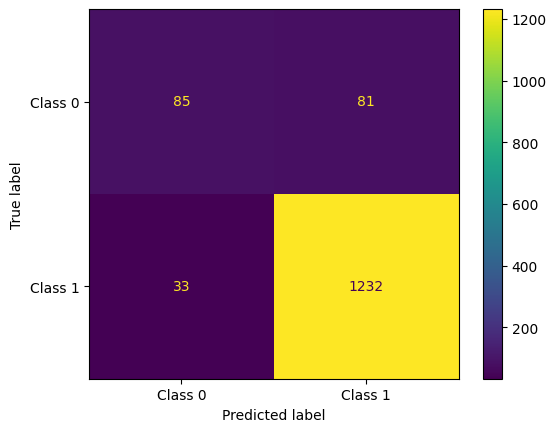

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Generate predictions
predictions = trainer.predict(test_tokenized)
predicted_labels = predictions.predictions.argmax(axis=-1)

# Classification report
print(classification_report(test_tokenized["label"], predicted_labels))

# Confusion matrix
cm = confusion_matrix(test_tokenized["label"], predicted_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])
disp.plot()

###Error Analysis

In [ ]:
true_labels = y_test.tolist()
pred_labels = preds.tolist()
texts = X_test.tolist()

error_df0 = pd.DataFrame({
    'text': texts,
    'actual': true_labels,
    'predicted': pred_labels
})

In [ ]:
# Inspect misclassified samples
misclassified_0 = error_df0[error_df0['actual'] != error_df0['predicted']]

print("Jumlah total error:", len(misclassified_0))
display(misclassified_0.sample(10, random_state=42))

misclassified_0.to_csv('misclassified0.csv', index=False)

Jumlah total error: 171


,text,actual,predicted
1004,wait mom always use olay grow like typical tee...,0,1
469,best market try numerous product otc expensive...,0,1
481,proven perfect product excelent,0,1
1350,peaceful good previous album terrible would st...,1,0
1585,love product prefer use clorox brand others qu...,0,1
759,cheesy poof niece love always go,0,1
1277,messy kid use quite often year old spreading...,0,1
1025,mixed feeling work wonder work pet shorter hai...,1,0
1057,finally row come late franchise see part pie...,0,1
1052,ok d could better entire movie wasnt could d...,0,1


###sample df0

In [ ]:
sampled_df0 = error_df0.sample(n=300, random_state=42)
sampled_df0

,text,actual,predicted
1613,great workout fan leslies several year year...,1,1
65,fabu vacuum quite bit research hepa vacuum set...,0,1
700,good smell effective like smell effectiveness ...,0,1
938,great juicer previously purchase diferent juic...,1,1
1623,handle broken twice like vacuum huge exception...,0,0
...,...,...,...
71,easy apply greasy overpower smell complaint sp...,1,1
1173,streak film product near work successfully cle...,1,1
259,nice answer look like nice answer organize pre...,1,1
51,awesome great product would recommend product ...,1,1


In [ ]:
# Inspect misclassified samples
misclassified_sample0 = sampled_df0[sampled_df0['actual'] != sampled_df0['predicted']]

print("Jumlah total error:", len(misclassified_sample0))
display(misclassified_sample0.sample(10, random_state=42))

Jumlah total error: 18


,text,actual,predicted
65,fabu vacuum quite bit research hepa vacuum set...,0,1
700,good smell effective like smell effectiveness ...,0,1
845,dont like new scent use shampoo year make hair...,1,0
247,doesnt work frustrate ive use windex year s...,1,0
607,like like like like like v like like like like...,0,1
1748,fun excite mixture cast mission make story lea...,0,1
759,cheesy poof niece love always go,0,1
383,bad conditioner bad shampoo absolutely nothing...,1,0
1205,really disappointed decide try conditioner thi...,1,0
1163,love airplane grandson take movie everywhere g...,0,1


In [ ]:
sampled_with_acc_0 = sampled_df0.copy()

# Add column acc_b to the sampled copy
sampled_with_acc_0['acc_b'] = sampled_with_acc_0['text'].apply(
    lambda x: 0 if x in misclassified_sample0['text'].values else 1
)

# Show result
display(sampled_with_acc_0)

,text,actual,predicted,acc_b
1613,great workout fan leslies several year year...,1,1,1
65,fabu vacuum quite bit research hepa vacuum set...,0,1,0
700,good smell effective like smell effectiveness ...,0,1,0
938,great juicer previously purchase diferent juic...,1,1,1
1623,handle broken twice like vacuum huge exception...,0,0,1
...,...,...,...,...
71,easy apply greasy overpower smell complaint sp...,1,1,1
1173,streak film product near work successfully cle...,1,1,1
259,nice answer look like nice answer organize pre...,1,1,1
51,awesome great product would recommend product ...,1,1,1


In [ ]:
sampled_with_acc_0.to_csv('topik0_sampel.csv', index=False)

##Topik 1

###Training

In [ ]:
df_topik1 = pd.read_csv('topik1.csv',\
                      encoding='latin-1')
display(df_topik1.sample(n=5, random_state=42))

,text,label_st1,sentiment
5653,clorox disinfect wipe awesome use clorox disin...,1,1
6978,great movie grand child grand child watch movi...,1,1
623,clorox wipe r awesome love clorox wipe conveni...,1,1
8220,awesome wipe love easy acessible canister dont...,1,1
8275,get job do really clean disinfects need clean ...,1,1


In [ ]:
x=df_topik1['text']
y=df_topik1['sentiment']
print("Checking distribution of +ve and -ve review sentiment: \n{}".format(y.value_counts(normalize=True)))
# Split the dataset into test and train
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=50)

# As we saw above that data is imbalanced, balance training data using over sampling

ros = over_sampling.RandomOverSampler(random_state=0)
X_train, y_train = ros.fit_resample(pd.DataFrame(X_train), pd.Series(y_train))
print("Checking distribution of +ve and -ve review sentiment after oversampling: \n{}".format(y_train.value_counts(normalize=True)))
# Convert into list of string
X_train = X_train['text'].tolist()

Checking distribution of +ve and -ve review sentiment: 
sentiment
1    0.897717
0    0.102283
Name: proportion, dtype: float64
Checking distribution of +ve and -ve review sentiment after oversampling: 
sentiment
1    0.5
0    0.5
Name: proportion, dtype: float64


In [ ]:
# Make Huggingface Dataset
train_data = Dataset.from_dict({"text": X_train, "label": y_train})
test_data = Dataset.from_dict({"text": X_test, "label": y_test})

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

train_tokenized = train_data.map(tokenize, batched=True)
test_tokenized = test_data.map(tokenize, batched=True)

Map:   0%|          | 0/11490 [00:00<?, ? examples/s]

Map:   0%|          | 0/2734 [00:00<?, ? examples/s]

In [ ]:
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
training_args = TrainingArguments(
    output_dir='./results', # All files generated during training will be stored here
    num_train_epochs=3, # The model will be trained for 3 full epochs unless the step limit (max_steps) is reached first
    per_device_train_batch_size=16, # Training batch size per device (GPU or CPU).
    per_device_eval_batch_size=64, # Evaluation batch size per device (GPU or CPU).
    weight_decay=0.01, # Weight decay rate: this technique helps to avoid overfitting, penalizing large weights in the neural network
    logging_dir='./logs', # Directory where training logs will be stored
    eval_strategy="epoch",
    save_strategy="epoch",  # Range of steps after which the model will be saved
    logging_steps=10,  # Range of steps after which log information will be recorded
)

In [ ]:
trainer = Trainer(
    model=model, # The pre-trained model that you want to fine-tune or train
    args=training_args, # The training arguments that specify the configurations for the training process
    train_dataset=train_tokenized, # The dataset used for training the model
    eval_dataset=test_tokenized # The dataset used for evaluating the model during training
)

# Start training
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.152600,0.262098
2,0.097400,0.375878
3,0.009300,0.507389


TrainOutput(global_step=2157, training_loss=0.11083830889315709, metrics={'train_runtime': 856.0526, 'train_samples_per_second': 40.266, 'train_steps_per_second': 2.52, 'total_flos': 2267359519564800.0, 'train_loss': 0.11083830889315709, 'epoch': 3.0})

In [ ]:
preds_output = trainer.predict(test_tokenized)
preds = preds_output.predictions.argmax(-1)

from sklearn.metrics import classification_report
print(classification_report(y_test, preds))

              precision    recall  f1-score   support

           0       0.77      0.55      0.64       299
           1       0.95      0.98      0.96      2435

    accuracy                           0.93      2734
   macro avg       0.86      0.76      0.80      2734
weighted avg       0.93      0.93      0.93      2734



###Error Analysis

In [ ]:
true_labels = y_test.tolist()
pred_labels = preds.tolist()
texts = X_test.tolist()

error_df1 = pd.DataFrame({
    'text': texts,
    'actual': true_labels,
    'predicted': pred_labels
})

In [ ]:
# Inspect misclassified samples
misclassified_1 = error_df1[error_df1['actual'] != error_df1['predicted']]

print("Jumlah total error:", len(misclassified_1))
display(misclassified_1.sample(10, random_state=42))

misclassified_1.to_csv('misclassified1.csv', index=False)

Jumlah total error: 184


,text,actual,predicted
299,happy guess pay attention see clorox bathroom ...,1,0
624,fun movie amuse farce really small child,0,1
2372,handy convenient keep bathroom make cleaning b...,0,1
1522,best chili ever chili come house,0,1
2219,like clorox wipe like clorox product feel like...,1,0
227,clean quick constantly reach clorox wipe clean...,1,0
360,awesome product clorox wipe get job do quickly...,0,1
1041,chili selection daughter luvs make chili dog p...,1,0
1636,awesome wipe ever little kid clorox wipe handy...,0,1
1364,love product use home well vehicle,0,1


###sample df1

In [ ]:
sampled_df1 = error_df1.sample(n=300, random_state=42)
sampled_df1

,text,actual,predicted
1001,wipe clean disinfect pleasant scent clorox wip...,1,1
1837,great gift grand kid love highly recommend,1,1
2480,excellent product love clorox product clean wh...,1,1
942,great product great product easy use keep ever...,1,1
73,love wipe love clorox wipe use clean need revi...,1,1
...,...,...,...
415,smell great love disinfect power clorox wipe a...,1,1
2691,excellent bug killer favorite product use espe...,1,1
1270,clean love esp new scent review collect part p...,1,1
1253,wouldnt know use clorox wipe everything always...,1,1


In [ ]:
# Inspect misclassified samples
misclassified_sample1 = sampled_df1[sampled_df1['actual'] != sampled_df1['predicted']]

print("Jumlah total error:", len(misclassified_sample1))
display(misclassified_sample1.sample(10, random_state=42))

Jumlah total error: 18


,text,actual,predicted
485,trap good open bag cant stop eating,0,1
270,great product overallmel wipe smell great conv...,0,1
1064,product clorox product always perform theyre d...,0,1
1885,amaze power product outdoes even commercial gl...,0,1
1029,chili cheese hot dog expensive,0,1
43,m clorox wipe inexpensive clean well especiall...,0,1
173,well builtsturdyattractive functional go perfe...,0,1
2441,nothing say work excessive energy use keep car...,1,0
354,love wipe good use everything never disappoint...,0,1
1187,great kill meanie germ use wipe everywhere hom...,0,1


In [ ]:
sampled_with_acc_1 = sampled_df1.copy()
sampled_with_acc_1['acc_c'] = sampled_with_acc_1['text'].apply(
    lambda x: 0 if x in misclassified_sample1['text'].values else 1
)
display(sampled_with_acc_1)

,text,actual,predicted,acc_c
1001,wipe clean disinfect pleasant scent clorox wip...,1,1,1
1837,great gift grand kid love highly recommend,1,1,1
2480,excellent product love clorox product clean wh...,1,1,1
942,great product great product easy use keep ever...,1,1,1
73,love wipe love clorox wipe use clean need revi...,1,1,1
...,...,...,...,...
415,smell great love disinfect power clorox wipe a...,1,1,1
2691,excellent bug killer favorite product use espe...,1,1,1
1270,clean love esp new scent review collect part p...,1,1,1
1253,wouldnt know use clorox wipe everything always...,1,1,1


In [ ]:
sampled_with_acc_1.to_csv('topik1_sampel.csv', index=False)

##Topik 2

###Training

In [ ]:
df_topik2 = pd.read_csv('topik2.csv',\
                      encoding='latin-1')
display(df_topik2.sample(n=5, random_state=42))

,text,label_st1,sentiment
324,great movie series watch love resident evil mo...,2,0
5395,great idea really liked concept folder wish se...,2,1
6084,excellent product ready index double column ta...,2,1
6323,incredible remake film shot humorously lots fa...,2,1
381,great sequel funny scene wife love first get s...,2,1


In [ ]:
x=df_topik2['text']
y=df_topik2['sentiment']
print("Checking distribution of +ve and -ve review sentiment: \n{}".format(y.value_counts(normalize=True)))
# Split the dataset into test and train
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=50)

# As we saw above that data is imbalanced, balance training data using over sampling

ros = over_sampling.RandomOverSampler(random_state=0)
X_train, y_train = ros.fit_resample(pd.DataFrame(X_train), pd.Series(y_train))
print("Checking distribution of +ve and -ve review sentiment after oversampling: \n{}".format(y_train.value_counts(normalize=True)))
# Convert into list of string
X_train = X_train['text'].tolist()

Checking distribution of +ve and -ve review sentiment: 
sentiment
1    0.911426
0    0.088574
Name: proportion, dtype: float64
Checking distribution of +ve and -ve review sentiment after oversampling: 
sentiment
1    0.5
0    0.5
Name: proportion, dtype: float64


In [ ]:
# Make Huggingface Dataset
train_data = Dataset.from_dict({"text": X_train, "label": y_train})
test_data = Dataset.from_dict({"text": X_test, "label": y_test})

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

train_tokenized = train_data.map(tokenize, batched=True)
test_tokenized = test_data.map(tokenize, batched=True)

Map:   0%|          | 0/8190 [00:00<?, ? examples/s]

Map:   0%|          | 0/1928 [00:00<?, ? examples/s]

In [ ]:
training_args = TrainingArguments(
    output_dir='./results', # All files generated during training will be stored here
    num_train_epochs=3, # The model will be trained for 3 full epochs unless the step limit (max_steps) is reached first
    per_device_train_batch_size=16, # Training batch size per device (GPU or CPU).
    per_device_eval_batch_size=64, # Evaluation batch size per device (GPU or CPU).
    weight_decay=0.01, # Weight decay rate: this technique helps to avoid overfitting, penalizing large weights in the neural network
    logging_dir='./logs', # Directory where training logs will be stored
    eval_strategy="epoch",
    save_strategy="epoch",  # Range of steps after which the model will be saved
    logging_steps=10,  # Range of steps after which log information will be recorded
)

In [ ]:
trainer = Trainer(
    model=model, # The pre-trained model that you want to fine-tune or train
    args=training_args, # The training arguments that specify the configurations for the training process
    train_dataset=train_tokenized, # The dataset used for training the model
    eval_dataset=test_tokenized # The dataset used for evaluating the model during training
)

# Start training
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.100800,0.276014
2,0.036900,0.387579
3,0.000300,0.447707


TrainOutput(global_step=1536, training_loss=0.09316707398617534, metrics={'train_runtime': 636.2032, 'train_samples_per_second': 38.62, 'train_steps_per_second': 2.414, 'total_flos': 1616159657548800.0, 'train_loss': 0.09316707398617534, 'epoch': 3.0})

In [ ]:
preds_output = trainer.predict(test_tokenized)
preds = preds_output.predictions.argmax(-1)

from sklearn.metrics import classification_report
print(classification_report(y_test, preds))

              precision    recall  f1-score   support

           0       0.69      0.57      0.62       168
           1       0.96      0.98      0.97      1760

    accuracy                           0.94      1928
   macro avg       0.83      0.77      0.80      1928
weighted avg       0.94      0.94      0.94      1928



###Error Analysis

In [ ]:
true_labels = y_test.tolist()
pred_labels = preds.tolist()
texts = X_test.tolist()

error_df2 = pd.DataFrame({
    'text': texts,
    'actual': true_labels,
    'predicted': pred_labels
})

In [ ]:
# Inspect misclassified samples
misclassified_2 = error_df2[error_df2['actual'] != error_df2['predicted']]

print("Jumlah total error:", len(misclassified_2))
display(misclassified_2.sample(10, random_state=42))

Jumlah total error: 115


,text,actual,predicted
1188,good d effect story line average love d effect,1,0
66,good problematic skin love,0,1
616,resident evil five disc collection take viewer...,0,1
1030,nice soothe soap,0,1
237,great box set movie lot fun watch get us refre...,0,1
679,movie play expect feel like review play conten...,0,1
1039,awesome product always use clorox four kid alw...,1,0
993,best wipe love smell cant go wrong clorox prod...,0,1
697,good doesnt like big scary monster expect movi...,0,1
241,plan year easy well make well thought room eve...,0,1


###Sample df2

In [ ]:
sampled_df2 = error_df2.sample(n=300, random_state=42)
sampled_df2

,text,actual,predicted
1118,great entertainment quite like classic japanes...,1,1
1652,king genre definitely best godzilla remake hom...,1,1
1863,great yearly report use office keep track acco...,1,1
941,great comeback classic movie good job pull aud...,1,1
331,dark shadow love dark humor movie eva green be...,1,1
...,...,...,...
591,funny movie fan cast movie push limit little b...,1,1
1160,refresh taste love product hard time find stor...,0,1
1189,godzilla godzilla movie fan like movie,0,1
1538,big guy back one best reboots movie series eve...,1,1


In [ ]:
# Inspect misclassified samples
misclassified_sample2 = sampled_df2[sampled_df2['actual'] != sampled_df2['predicted']]

print("Jumlah total error:", len(misclassified_sample2))
display(misclassified_sample2.sample(10, random_state=42))

misclassified_2.to_csv('misclassified2.csv', index=False)

Jumlah total error: 24


,text,actual,predicted
706,impressed wait thru movie finally get glimp...,0,1
879,godzilla back complaint fact movie focus bit m...,0,1
99,cute nephew love moviehe watch time,1,0
361,love color person aspergers syndrome put paper...,0,1
514,good ok movie worth price get black friday sale,1,0
849,run life bad reinvention d effect decentb mons...,1,0
1907,mike dave fun average comedy dark twist great ...,0,1
585,good stove fair price seem well build would bu...,0,1
993,best wipe love smell cant go wrong clorox prod...,0,1
1074,ben stiller amazingly funny script well do lot...,0,1


In [ ]:
sampled_with_acc_2 = sampled_df2.copy()
sampled_with_acc_2['acc_d'] = sampled_with_acc_2['text'].apply(
    lambda x: 0 if x in misclassified_sample2['text'].values else 1
)
display(sampled_with_acc_2)

,text,actual,predicted,acc_d
1118,great entertainment quite like classic japanes...,1,1,1
1652,king genre definitely best godzilla remake hom...,1,1,1
1863,great yearly report use office keep track acco...,1,1,1
941,great comeback classic movie good job pull aud...,1,1,1
331,dark shadow love dark humor movie eva green be...,1,1,1
...,...,...,...,...
591,funny movie fan cast movie push limit little b...,1,1,1
1160,refresh taste love product hard time find stor...,0,1,0
1189,godzilla godzilla movie fan like movie,0,1,0
1538,big guy back one best reboots movie series eve...,1,1,1


In [ ]:
sampled_with_acc_2.to_csv('topik2_sampel.csv', index=False)

##Topik 3

###Training

In [ ]:
df_topik3 = pd.read_csv('topik3.csv',\
                      encoding='latin-1')
display(df_topik3.sample(n=5, random_state=42))

,text,label_st1,sentiment
1025,great remake great movie action pack always en...,3,1
4006,pretty good movie good kid adult good sequel ...,3,1
2594,entertain like plane enjoy fire rescue good fo...,3,1
1817,bounce use bounce year love always use need tr...,3,1
1620,stuff amaze lip always problem get chap dry ev...,3,1


In [ ]:
x=df_topik3['text']
y=df_topik3['sentiment']
print("Checking distribution of +ve and -ve review sentiment: \n{}".format(y.value_counts(normalize=True)))
# Split the dataset into test and train
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=50)

# As we saw above that data is imbalanced, balance training data using over sampling

ros = over_sampling.RandomOverSampler(random_state=0)
X_train, y_train = ros.fit_resample(pd.DataFrame(X_train), pd.Series(y_train))
print("Checking distribution of +ve and -ve review sentiment after oversampling: \n{}".format(y_train.value_counts(normalize=True)))
# Convert into list of string
X_train = X_train['text'].tolist()

Checking distribution of +ve and -ve review sentiment: 
sentiment
1    0.859375
0    0.140625
Name: proportion, dtype: float64
Checking distribution of +ve and -ve review sentiment after oversampling: 
sentiment
1    0.5
0    0.5
Name: proportion, dtype: float64


In [ ]:
# Make Huggingface Dataset
train_data = Dataset.from_dict({"text": X_train, "label": y_train})
test_data = Dataset.from_dict({"text": X_test, "label": y_test})

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

train_tokenized = train_data.map(tokenize, batched=True)
test_tokenized = test_data.map(tokenize, batched=True)

Map:   0%|          | 0/6384 [00:00<?, ? examples/s]

Map:   0%|          | 0/1594 [00:00<?, ? examples/s]

In [ ]:
training_args = TrainingArguments(
    output_dir='./results', # All files generated during training will be stored here
    num_train_epochs=3, # The model will be trained for 3 full epochs unless the step limit (max_steps) is reached first
    per_device_train_batch_size=16, # Training batch size per device (GPU or CPU).
    per_device_eval_batch_size=64, # Evaluation batch size per device (GPU or CPU).
    weight_decay=0.01, # Weight decay rate: this technique helps to avoid overfitting, penalizing large weights in the neural network
    logging_dir='./logs', # Directory where training logs will be stored
    eval_strategy="epoch",
    save_strategy="epoch",  # Range of steps after which the model will be saved
    logging_steps=10,  # Range of steps after which log information will be recorded
)

In [ ]:
trainer = Trainer(
    model=model, # The pre-trained model that you want to fine-tune or train
    args=training_args, # The training arguments that specify the configurations for the training process
    train_dataset=train_tokenized, # The dataset used for training the model
    eval_dataset=test_tokenized # The dataset used for evaluating the model during training
)

# Start training
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.041700,0.428596
2,0.087800,0.515269
3,0.000300,0.600643


TrainOutput(global_step=1197, training_loss=0.10670899599440452, metrics={'train_runtime': 538.0106, 'train_samples_per_second': 35.598, 'train_steps_per_second': 2.225, 'total_flos': 1259775733063680.0, 'train_loss': 0.10670899599440452, 'epoch': 3.0})

In [ ]:
preds_output = trainer.predict(test_tokenized)
preds = preds_output.predictions.argmax(-1)

from sklearn.metrics import classification_report
print(classification_report(y_test, preds))

              precision    recall  f1-score   support

           0       0.77      0.59      0.67       221
           1       0.94      0.97      0.95      1373

    accuracy                           0.92      1594
   macro avg       0.85      0.78      0.81      1594
weighted avg       0.91      0.92      0.91      1594



###Error Analysis

In [ ]:
true_labels = y_test.tolist()
pred_labels = preds.tolist()
texts = X_test.tolist()

error_df3 = pd.DataFrame({
    'text': texts,
    'actual': true_labels,
    'predicted': pred_labels
})

In [ ]:
# Inspect misclassified samples
misclassified_3 = error_df3[error_df3['actual'] != error_df3['predicted']]

print("Jumlah total error:", len(misclassified_3))
display(misclassified_3.sample(10, random_state=42))

Jumlah total error: 130


,text,actual,predicted
622,terrible change good product nexxus xxtra gel ...,1,0
361,something mary greatsaturday morning movie wak...,0,1
167,pretty disappointed monkey cute music play lit...,0,1
282,breath always trust vicks vapor rub help breat...,0,1
1457,terribly disappointed ive rely old formula ...,1,0
633,tasty tasty high calorie,0,1
831,k jobplan buy chance review collect part promo...,1,0
1283,watery lipgloss think since call laquer would ...,0,1
941,bad worth look first go theater see new go dri...,1,0
224,awesome music jason job new cd see little soft...,0,1


###Sample df3

In [ ]:
sampled_df3 = error_df3.sample(n=300, random_state=42)
sampled_df3

,text,actual,predicted
917,exxtra gel nexxus exxtra gel long product buy ...,1,1
1120,touch gray black gray product easy use work co...,1,1
1276,super please find american grown black rice re...,1,1
361,something mary greatsaturday morning movie wak...,0,1
1483,magic lip love vaseline cocoa butter lip alway...,1,1
...,...,...,...
1564,amaze expect movie well first one certainly de...,1,1
1403,great love lip shimmer dont wear anything else...,1,1
495,poligrip last day good flavor,1,1
1383,lundberg wehani whole grain brown rice great p...,1,1


In [ ]:
# Inspect misclassified samples
misclassified_sample3 = sampled_df3[sampled_df3['actual'] != sampled_df3['predicted']]

print("Jumlah total error:", len(misclassified_sample3))
display(misclassified_sample3.sample(10, random_state=42))

misclassified_3.to_csv('misclassified3.csv', index=False)

Jumlah total error: 20


,text,actual,predicted
361,something mary greatsaturday morning movie wak...,0,1
693,ok movie son love movie find alright watch,0,1
584,lip color really lip product use like plum neu...,1,0
1080,terrible smell use previous gel product year g...,1,0
705,worth money worth every penny especially use b...,0,1
32,happy wife happy life wife love buy review col...,0,1
859,tube gritty one purchase tube gritty one purch...,1,0
135,great movie lot action planescars fan must get...,0,1
706,excellent soap sensitive skin use soap year me...,0,1
1079,great product discontinue stocking longer avai...,1,0


In [ ]:
sampled_with_acc_3 = sampled_df3.copy()
sampled_with_acc_3['acc_e'] = sampled_with_acc_3['text'].apply(
    lambda x: 0 if x in misclassified_sample3['text'].values else 1
)
display(sampled_with_acc_3)

,text,actual,predicted,acc_e
917,exxtra gel nexxus exxtra gel long product buy ...,1,1,1
1120,touch gray black gray product easy use work co...,1,1,1
1276,super please find american grown black rice re...,1,1,1
361,something mary greatsaturday morning movie wak...,0,1,0
1483,magic lip love vaseline cocoa butter lip alway...,1,1,1
...,...,...,...,...
1564,amaze expect movie well first one certainly de...,1,1,1
1403,great love lip shimmer dont wear anything else...,1,1,1
495,poligrip last day good flavor,1,1,1
1383,lundberg wehani whole grain brown rice great p...,1,1,1


In [ ]:
sampled_with_acc_3.to_csv('topik3_sampel.csv', index=False)